In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.stats import skew
import os
from sklearn.model_selection import train_test_split
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_squared_error
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

/kaggle/input/competitions/house-prices-advanced-regression-techniques/sample_submission.csv
/kaggle/input/competitions/house-prices-advanced-regression-techniques/data_description.txt
/kaggle/input/competitions/house-prices-advanced-regression-techniques/train.csv
/kaggle/input/competitions/house-prices-advanced-regression-techniques/test.csv


In [2]:
test = pd.read_csv('/kaggle/input/competitions/house-prices-advanced-regression-techniques/test.csv', index_col='Id')
test.info()

<class 'pandas.core.frame.DataFrame'>
Index: 1459 entries, 1461 to 2919
Data columns (total 79 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   MSSubClass     1459 non-null   int64  
 1   MSZoning       1455 non-null   object 
 2   LotFrontage    1232 non-null   float64
 3   LotArea        1459 non-null   int64  
 4   Street         1459 non-null   object 
 5   Alley          107 non-null    object 
 6   LotShape       1459 non-null   object 
 7   LandContour    1459 non-null   object 
 8   Utilities      1457 non-null   object 
 9   LotConfig      1459 non-null   object 
 10  LandSlope      1459 non-null   object 
 11  Neighborhood   1459 non-null   object 
 12  Condition1     1459 non-null   object 
 13  Condition2     1459 non-null   object 
 14  BldgType       1459 non-null   object 
 15  HouseStyle     1459 non-null   object 
 16  OverallQual    1459 non-null   int64  
 17  OverallCond    1459 non-null   int64  
 18  YearBuilt 

In [3]:
train = pd.read_csv('/kaggle/input/competitions/house-prices-advanced-regression-techniques/train.csv', index_col='Id')
display(train.head())
train.info()
display(train.describe())

,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,LotConfig,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
Id,,,,,,,,,,,,,,,,,,,,,
1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,Inside,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,FR2,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,Inside,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,Corner,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,FR2,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


<class 'pandas.core.frame.DataFrame'>
Index: 1460 entries, 1 to 1460
Data columns (total 80 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   MSSubClass     1460 non-null   int64  
 1   MSZoning       1460 non-null   object 
 2   LotFrontage    1201 non-null   float64
 3   LotArea        1460 non-null   int64  
 4   Street         1460 non-null   object 
 5   Alley          91 non-null     object 
 6   LotShape       1460 non-null   object 
 7   LandContour    1460 non-null   object 
 8   Utilities      1460 non-null   object 
 9   LotConfig      1460 non-null   object 
 10  LandSlope      1460 non-null   object 
 11  Neighborhood   1460 non-null   object 
 12  Condition1     1460 non-null   object 
 13  Condition2     1460 non-null   object 
 14  BldgType       1460 non-null   object 
 15  HouseStyle     1460 non-null   object 
 16  OverallQual    1460 non-null   int64  
 17  OverallCond    1460 non-null   int64  
 18  YearBuilt    

,MSSubClass,LotFrontage,LotArea,OverallQual,OverallCond,YearBuilt,YearRemodAdd,MasVnrArea,BsmtFinSF1,BsmtFinSF2,...,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,MiscVal,MoSold,YrSold,SalePrice
count,1460.000000,1201.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1452.000000,1460.000000,1460.000000,...,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000
mean,56.897260,70.049958,10516.828082,6.099315,5.575342,1971.267808,1984.865753,103.685262,443.639726,46.549315,...,94.244521,46.660274,21.954110,3.409589,15.060959,2.758904,43.489041,6.321918,2007.815753,180921.195890
std,42.300571,24.284752,9981.264932,1.382997,1.112799,30.202904,20.645407,181.066207,456.098091,161.319273,...,125.338794,66.256028,61.119149,29.317331,55.757415,40.177307,496.123024,2.703626,1.328095,79442.502883
min,20.000000,21.000000,1300.000000,1.000000,1.000000,1872.000000,1950.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,2006.000000,34900.000000
25%,20.000000,59.000000,7553.500000,5.000000,5.000000,1954.000000,1967.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,5.000000,2007.000000,129975.000000
50%,50.000000,69.000000,9478.500000,6.000000,5.000000,1973.000000,1994.000000,0.000000,383.500000,0.000000,...,0.000000,25.000000,0.000000,0.000000,0.000000,0.000000,0.000000,6.000000,2008.000000,163000.000000
75%,70.000000,80.000000,11601.500000,7.000000,6.000000,2000.000000,2004.000000,166.000000,712.250000,0.000000,...,168.000000,68.000000,0.000000,0.000000,0.000000,0.000000,0.000000,8.000000,2009.000000,214000.000000
max,190.000000,313.000000,215245.000000,10.000000,9.000000,2010.000000,2010.000000,1600.000000,5644.000000,1474.000000,...,857.000000,547.000000,552.000000,508.000000,480.000000,738.000000,15500.000000,12.000000,2010.000000,755000.000000


In [4]:
features = train.drop('SalePrice', axis=1)
cat_cols = features.select_dtypes(include=['object']).columns
num_cols = features.select_dtypes(exclude=['object']).columns

# categorie mancanti
for col in cat_cols:
    train[col] = train[col].fillna('None')
    test[col] = test[col].fillna('None')

# mediana per le numeriche
for col in num_cols:
    median_train = train[col].median()
    train[col] = train[col].fillna(median_train)
    test[col] = test[col].fillna(median_train)

# verifica finale
print(f"Valori vuoti in train: {train.isnull().sum().max()}")
print(f"Valori vuoti in test: {test.isnull().sum().max()}")

Valori vuoti in train: 0
Valori vuoti in test: 0


In [5]:
# valori outliers
res_outliers = []

for col in num_cols:
    Q1 = train[col].quantile(0.25)
    Q3 = train[col].quantile(0.75)
    IQR = Q3 - Q1
    
    lim_min = Q1 - 1.5 * IQR
    lim_max = Q3 + 1.5 * IQR
    
    outliers = train[(train[col] < lim_min) | (train[col] > lim_max)][col]
    
    if len(outliers) > 0:
        res_outliers.append({
            'Colonna': col,
            'N_Outliers': len(outliers),
            'Min_Outlier': outliers.min(),
            'Max_Outlier': outliers.max()
        })

df_outliers = pd.DataFrame(res_outliers).sort_values(by='N_Outliers', ascending=False)
print(df_outliers)

          Colonna  N_Outliers  Min_Outlier  Max_Outlier
26  EnclosedPorch         208         19.0        552.0
8      BsmtFinSF2         167         28.0       1474.0
4     OverallCond         125          1.0          9.0
28    ScreenPorch         116         40.0        480.0
1     LotFrontage         106         21.0        313.0
0      MSSubClass         103        160.0        190.0
6      MasVnrArea          98        412.0       1600.0
16   BsmtHalfBath          82          1.0          2.0
25    OpenPorchSF          77        172.0        547.0
2         LotArea          69       1300.0     215245.0
18   KitchenAbvGr          68          0.0          3.0
10    TotalBsmtSF          61          0.0       6110.0
30        MiscVal          52         54.0      15500.0
17   BedroomAbvGr          35          0.0          8.0
24     WoodDeckSF          32        421.0        857.0
14      GrLivArea          31       2775.0       5642.0
19   TotRmsAbvGrd          30         11.0      

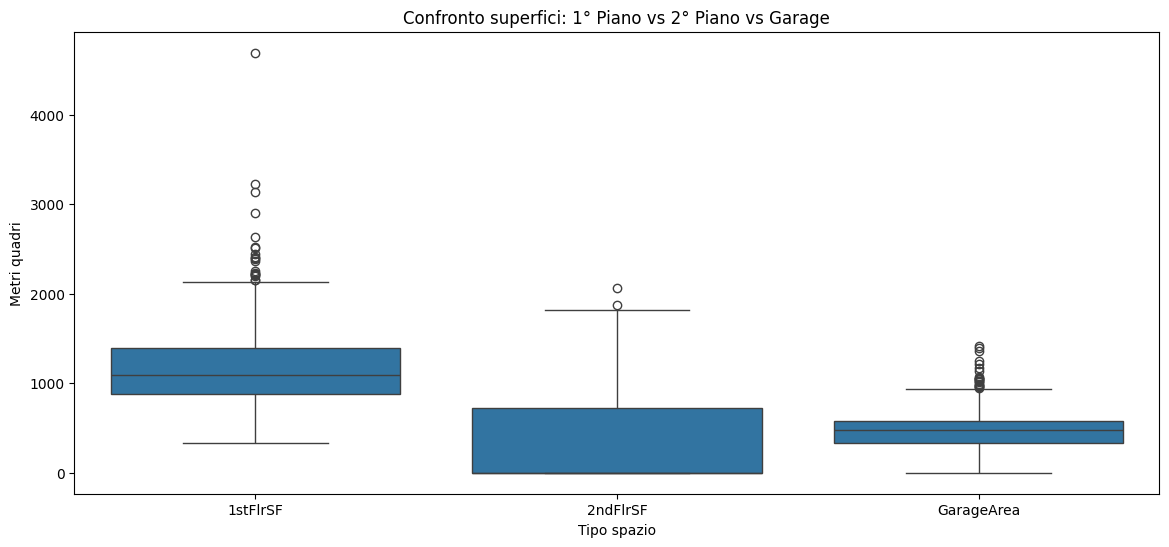

In [6]:
# colonne superficie
surface_cols = ['1stFlrSF', '2ndFlrSF', 'GarageArea']
df_surface = train[surface_cols]

df_long = df_surface.melt(var_name='Tipo spazio', value_name='Metri quadri')

plt.figure(figsize=(14,6))
sns.boxplot(x='Tipo spazio', y='Metri quadri', data=df_long)
plt.title('Confronto superfici: 1° Piano vs 2° Piano vs Garage')
plt.show()

In [7]:
# rimuoviamo outliers esagerati
train = train.drop(train[train['GrLivArea'] > 4500].index)
train = train.drop(train[train['LotArea'] > 100000].index)
train = train.drop(train[train['1stFlrSF'] > 4000].index)

print(f"Dataset dopo la potatura: {train.shape}")

Dataset dopo la potatura: (1454, 80)


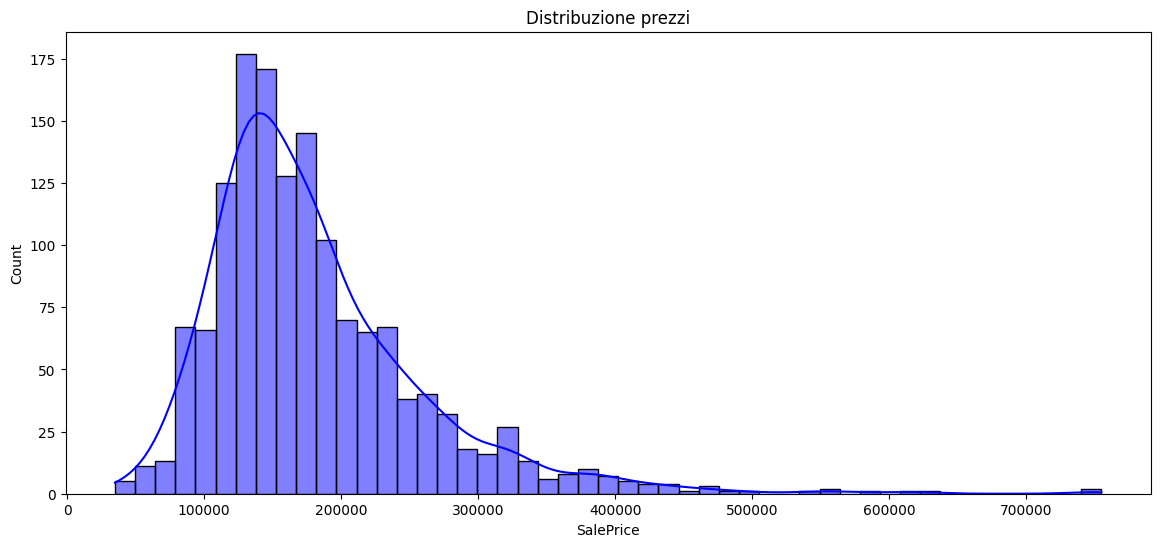

In [8]:
plt.figure(figsize=(14, 6))
sns.histplot(train['SalePrice'], kde=True, color='blue')
plt.title('Distribuzione prezzi')
plt.show()

In [9]:
# applichiamo il logaritmo sui prezzi
train['SalePrice'] = np.log1p(train['SalePrice'])

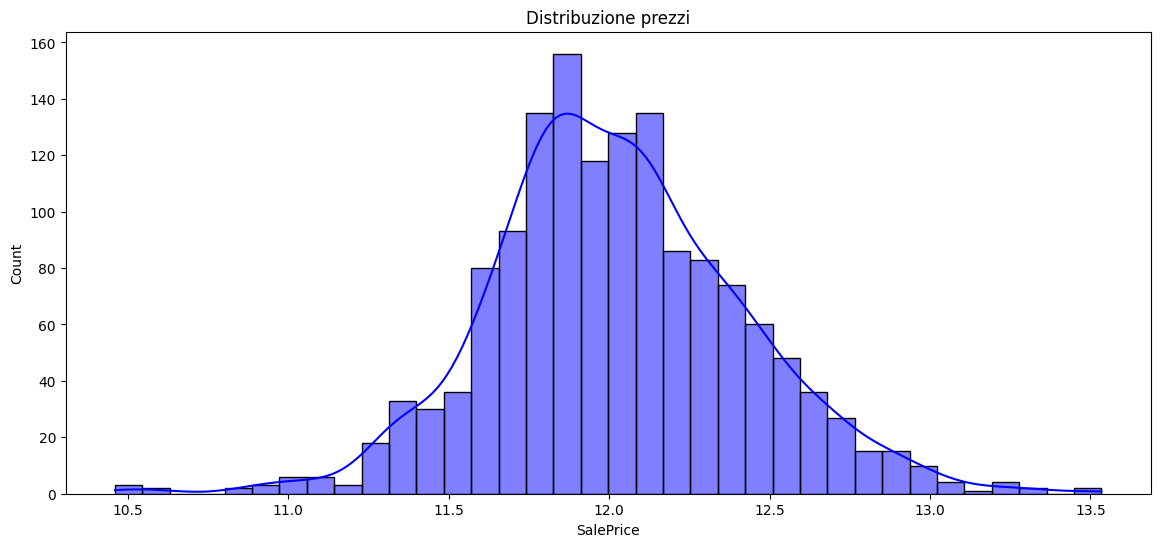

In [10]:
plt.figure(figsize=(14, 6))
sns.histplot(train['SalePrice'], kde=True, color='blue')
plt.title('Distribuzione prezzi')
plt.show()

In [11]:
# calcoliamo le correlazioni
corr = train.corr(numeric_only=True)['SalePrice'].sort_values(ascending=False)
corr.head(10)

SalePrice       1.000000
OverallQual     0.823161
GrLivArea       0.724709
GarageCars      0.681935
GarageArea      0.657123
TotalBsmtSF     0.645372
1stFlrSF        0.618170
FullBath        0.595124
YearBuilt       0.589629
YearRemodAdd    0.568487
Name: SalePrice, dtype: float64

In [12]:
# calcoliamo l'asimmetria nelle feature numeriche
numeric_feats = train.dtypes[train.dtypes != "object"].index
skewed_feats = train[numeric_feats].apply(lambda x: skew(x.dropna())).sort_values(ascending=False)

print("Asimmetria nelle feature numeriche:")
print(skewed_feats.head(10))

Asimmetria nelle feature numeriche:
MiscVal          24.469277
PoolArea         15.910404
3SsnPorch        10.272009
LowQualFinSF      8.982890
KitchenAbvGr      4.473226
BsmtFinSF2        4.279205
BsmtHalfBath      4.121397
ScreenPorch       4.108107
LotArea           3.932476
EnclosedPorch     3.078561
dtype: float64


In [13]:
# selezioniamo le feature con asimmetria alta
high_skew_cols = skewed_feats[abs(skewed_feats) > 0.75].index

# applichiamo il logaritmo a entrambe
for col in high_skew_cols:
    train[col] = np.log1p(train[col])
    test[col] = np.log1p(test[col])

print(f"Abbiamo normalizzato {len(high_skew_cols)} colonne.")

Abbiamo normalizzato 20 colonne.


In [14]:
y = train['SalePrice']
x = train.drop('SalePrice', axis=1)
x = pd.get_dummies(x)
test = pd.get_dummies(test)
x, test = x.align(test, join='left', axis=1, fill_value=0)

In [15]:
x.head()

,MSSubClass,LotFrontage,LotArea,OverallQual,OverallCond,YearBuilt,YearRemodAdd,MasVnrArea,BsmtFinSF1,BsmtFinSF2,...,SaleType_ConLw,SaleType_New,SaleType_Oth,SaleType_WD,SaleCondition_Abnorml,SaleCondition_AdjLand,SaleCondition_Alloca,SaleCondition_Family,SaleCondition_Normal,SaleCondition_Partial
Id,,,,,,,,,,,,,,,,,,,,,
1,4.110874,4.189655,9.042040,7,5,2003,2003,5.283204,6.561031,0.0,...,False,False,False,True,False,False,False,False,True,False
2,3.044522,4.394449,9.169623,6,8,1976,1976,0.000000,6.886532,0.0,...,False,False,False,True,False,False,False,False,True,False
3,4.110874,4.234107,9.328212,7,5,2001,2002,5.093750,6.188264,0.0,...,False,False,False,True,False,False,False,False,True,False
4,4.262680,4.110874,9.164401,7,5,1915,1970,0.000000,5.379897,0.0,...,False,False,False,True,True,False,False,False,False,False
5,4.110874,4.442651,9.565284,8,5,2000,2000,5.860786,6.486161,0.0,...,False,False,False,True,False,False,False,False,True,False


In [16]:
test.head()

,MSSubClass,LotFrontage,LotArea,OverallQual,OverallCond,YearBuilt,YearRemodAdd,MasVnrArea,BsmtFinSF1,BsmtFinSF2,...,SaleType_ConLw,SaleType_New,SaleType_Oth,SaleType_WD,SaleCondition_Abnorml,SaleCondition_AdjLand,SaleCondition_Alloca,SaleCondition_Family,SaleCondition_Normal,SaleCondition_Partial
Id,,,,,,,,,,,,,,,,,,,,,
1461,3.044522,4.394449,9.360741,5,6,1961,1961,0.000000,6.150603,4.976734,...,False,False,False,True,False,False,False,False,True,False
1462,3.044522,4.406719,9.565775,6,6,1958,1958,4.691348,6.828712,0.000000,...,False,False,False,True,False,False,False,False,True,False
1463,4.110874,4.317488,9.534668,5,5,1997,1998,0.000000,6.674561,0.000000,...,False,False,False,True,False,False,False,False,True,False
1464,4.110874,4.369448,9.208238,6,6,1998,1998,3.044522,6.401917,0.000000,...,False,False,False,True,False,False,False,False,True,False
1465,4.795791,3.784190,8.518392,8,5,1992,1992,0.000000,5.575949,0.000000,...,False,False,False,True,False,False,False,False,True,False


In [17]:
# controlliamo se le colonne sono identiche in x e test
equals = x.columns.equals(test.columns)
print(f"I dataset sono perfettamente allineati? {equals}")

if not equals:
    # colonne in x ma non in test
    not_in_test = set(x.columns) - set(test.columns)
    # colonne in test ma non in x
    not_in_train = set(test.columns) - set(x.columns)
    
    print(f"Colonne mancanti nel Test: {len(not_in_test)}")
    print(f"Colonne extra nel Test: {len(not_in_train)}")

I dataset sono perfettamente allineati? True


In [18]:
x_train, x_val, y_train, y_val = train_test_split(x, y, test_size=0.2, random_state=42)

In [19]:
model = Ridge(alpha=10)
model.fit(x_train, y_train)

preds = model.predict(x_val)

rmse = np.sqrt(mean_squared_error(y_val, preds))
print(f"RMSE sul set di validazione: {rmse:.5f}")

RMSE sul set di validazione: 0.11728


In [20]:
# addestramento su tutto il dataset
model.fit(x, y)

Ridge(alpha=10)

In [21]:
final_preds_log = model.predict(test)
final_preds = np.expm1(final_preds_log)

In [22]:
submission = pd.DataFrame({
    'Id': test.index,
    'SalePrice': final_preds
})
submission.to_csv('submission.csv', index=False)